# Neural network #
1D convolutional network (PyTorch) on sliding windows: the consumption of the 168 hours ending 145 hours before the target hour and the temperature forecast for the 168 hours up to it, plus location, hour, weekday, holiday and the weather (precipitation, snowfall, wind) for the target hour. Same test period as `xgboost.ipynb`, tuned with Optuna on three rolling validation windows at the end of the training data, so the test set is only used once at the end. The final forecast is the mean of networks trained with different seeds.

Requires `pip install torch optuna`.

In [ ]:
import time
import numpy as np
import pandas as pd
import torch
import optuna
from forecast_checks import (LeakageChecker, ForecastValidator, MakeTrainingData, permutation_importance,
                             temperature_noise_sensitivity, save_tables)
from neural_network_helper import (SEED, MAX_EPOCHS, STATIC_COLS, WEATHER_COLS, WindowScaler, train_model, ensemble_fit,
                                   ensemble_predict, ensemble_forecast, target_day_temperature)

torch.manual_seed(SEED)
np.random.seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [2]:
SCOORING_METRIC="root_mean_square_error"

In [3]:
#One week of hours covers both the daily and the weekly cycle
WINDOW_HOURS = 168
trainer = MakeTrainingData(window_hours=WINDOW_HOURS)
df = trainer.df

In [ ]:
#Leakage check of the windows: scramble everything unknown when a day is forecast and check that its windows do not change.
#Random days, plus the week after the October DST change, where a consumption window starting 144 h back would leak.
#The weather columns are forecasts like temperature, so they are known up to and including the target day
checker = LeakageChecker(df[["location", "time", "consumption", "temperature", *WEATHER_COLS]],
                         forecast_cols=["temperature", *WEATHER_COLS])
build_windows = lambda raw: MakeTrainingData.add_sliding_window(raw, WINDOW_HOURS)
checker.check_features(build_windows)
checker.check_features(build_windows, target_days=pd.date_range("2022-10-30", "2022-11-05"))

In [ ]:
#Same temporal split as xgboost.ipynb; the row labels of the split index trainer.df
data = trainer.get_train_test()
train, test = (df.loc[data[part]["feature"].index] for part in ("train", "test"))
LeakageChecker.check_split(train["date"], test["date"])

#Optuna tunes on three consecutive 2-week windows at the end of the training period (late autumn and winter, like the test period).
#Each window is trained on everything up to 6 days before it; several windows make the choice of model less dependent on one period.
#xgboost.ipynb uses the same windows for its validation forecasts, so error_analysis.ipynb can compare the models on them
folds = [(train.loc[fit], train.loc[val]) for fit, val in MakeTrainingData.validation_windows(train["date"])]
for fit, val in folds:
    print(f"fit: {fit['date'].min().date()} - {fit['date'].max().date()}, val: {val['date'].min().date()} - {val['date'].max().date()}")

In [ ]:
feats = ["location", "hour", "weekday", *STATIC_COLS, *trainer.consumption_window, *trainer.temperature_window]
LeakageChecker.check_feature_names(feats)
LOCATIONS = sorted(df["location"].unique())

#The network cannot take missing values. Also require the point lags, so the test hours are the same as in xgboost.ipynb
scored = feats + ["consumption_6days_ago", "consumption_7days_ago", "consumption_14days_ago"]
train, test = (d.dropna(subset=scored) for d in (train, test))
folds = [(fit.dropna(subset=scored), val.dropna(subset=scored)) for fit, val in folds]


def make_scaler(data):
    return WindowScaler(data, trainer.consumption_window, trainer.temperature_window, LOCATIONS)

In [7]:
#Tune on the validation windows; each window's scaler only sees its own fit period
fold_sets = []
for fit, val in folds:
    fit_scaler = make_scaler(fit)
    fold_sets.append((fit_scaler.X(fit), fit_scaler.y(fit), (fit_scaler.X(val), val["consumption"], fit_scaler, val)))
N_TRIALS = 40


def objective(trial):
    params = {"n_conv": trial.suggest_int("n_conv", 1, 3),
              "channels": trial.suggest_categorical("channels", [16, 32, 64]),
              "kernel": trial.suggest_categorical("kernel", [3, 5, 7]),
              "hidden": trial.suggest_categorical("hidden", [32, 64, 128]),
              "dropout": trial.suggest_float("dropout", 0.0, 0.3),
              "lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),
              "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
              "batch_size": trial.suggest_categorical("batch_size", [256, 512, 1024])}
    maes, epochs = [], []
    for step, (X_fit, y_fit, val_set) in enumerate(fold_sets):
        _, mae, best_epoch = train_model(params, X_fit, y_fit, MAX_EPOCHS, val=val_set)
        maes.append(mae)
        epochs.append(best_epoch)
        #Every trial sees the windows in the same order, so the running mean can be compared between trials
        trial.report(np.mean(maes), step)
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr("best_epoch", round(np.mean(epochs)))
    trial.set_user_attr("fold_maes", maes)
    return np.mean(maes)


start = time.time()
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=0))
#Fixed number of trials, not a time budget: with a timeout the number of trials (and so the chosen model) depends on machine speed
study.optimize(objective, n_trials=N_TRIALS)
pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)
print(f"{len(study.trials)} trials ({pruned} pruned) in {time.time() - start:.0f} s")
print("Best mean validation MAE:", study.best_value, "per window:", study.best_trial.user_attrs["fold_maes"],
      "at epoch", study.best_trial.user_attrs["best_epoch"])
study.best_params

40 trials (23 pruned) in 2947 s
Best mean validation MAE: 0.3275971320706088 per window: [0.28975260790270446, 0.32790058559721535, 0.3651382027119065] at epoch 12


{'n_conv': 1,
 'channels': 16,
 'kernel': 7,
 'hidden': 128,
 'dropout': 0.1090888807137882,
 'lr': 0.008781408196485976,
 'weight_decay': 0.0007715105777813049,
 'batch_size': 512}

In [ ]:
#Check the chosen model on every validation window before touching the test set: per location, so a location where it
#loses to the baseline shows up here. The windows contain Christmas and New Year, which the test period does not,
#so their forecasts are saved for the holiday analysis in error_analysis.ipynb.
#The networks of each window are kept and saved below, for the local heads in local_vs_global.ipynb
fold_models = [ensemble_fit(study.best_params, study.best_trial.user_attrs["best_epoch"], fit, make_scaler(fit))
               for fit, _ in folds]
val_pred = [ensemble_predict(networks, val, make_scaler(fit)) for networks, (fit, val) in zip(fold_models, folds)]
val_all = pd.concat([val for _, val in folds])
val_validator = (ForecastValidator(val_all["consumption"], groups=val_all["location"])
                 .add("Same hour last week", val_all["consumption_7days_ago"], baseline=True)
                 .add("Neural network", np.concatenate(val_pred)))
val_validator.save_predictions("results/neural_network_validation_predictions.json")
val_validator.per_group(skill=True)

In [ ]:
#Refit on the whole training period with the best parameters and number of epochs, then predict the test period once.
#The networks are kept, so the robustness checks below can predict without retraining
scaler = make_scaler(train)
models = ensemble_fit(study.best_params, study.best_trial.user_attrs["best_epoch"], train, scaler)
predict_mw = lambda data: ensemble_predict(models, data, scaler)
pred = predict_mw(test)
print(f"Total training time: {time.time() - start:.0f} s")
test = test.assign(pred=pred)

In [ ]:
#Save the networks, so local_vs_global.ipynb can reuse the trained convolutions without retraining them
torch.save({"params": study.best_params, "epochs": study.best_trial.user_attrs["best_epoch"],
            "test": [model.state_dict() for model in models],
            "folds": [[model.state_dict() for model in networks] for networks in fold_models]},
           "results/neural_network_models.pt")

In [10]:
#Same hours as the comparison in xgboost.ipynb (test rows where every lag exists), so the tables can be compared directly
validator = (ForecastValidator(test["consumption"], groups=test["location"])
             .add("Same hour last week", test["consumption_7days_ago"], baseline=True)
             .add("Neural network", test["pred"]))
validator.summary()

,mae,rmse,nmae,bias
Same hour last week,0.494720,0.806999,8.983281,0.033943
Neural network,0.260906,0.374982,4.737603,0.063378


In [ ]:
validator.save_to_json("results/neural_network.json")
validator.save_predictions("results/neural_network_predictions.json")

In [ ]:
#Robustness on the test period, used by error_analysis.ipynb. Importance: how much the MAE grows when a group of inputs
#is shuffled (same groups as xgboost.ipynb). The test period has no holidays, so holiday is part of calendar.
#Temperature noise: the error of a real day-ahead forecast, added to the part of the temperature window in the target day
FEATURE_GROUPS = {"consumption": trainer.consumption_window, "temperature": trainer.temperature_window,
                  "calendar": ["hour", "weekday", "holiday"], "other weather": WEATHER_COLS}
importance = permutation_importance(predict_mw, test, test["consumption"], FEATURE_GROUPS)
temperature_noise = temperature_noise_sensitivity(predict_mw, test, test["consumption"], test["date"],
                                                  trainer.temperature_window,
                                                  in_target_day=target_day_temperature(test, trainer.temperature_window))
save_tables("results/neural_network_robustness.json", importance=importance, temperature_noise=temperature_noise)
importance

In [ ]:
temperature_noise

In [12]:
validator.per_group()

mae      rmse       nmae      bias
model               group                                               
Same hour last week bergen       0.346885  0.419259  10.768142  0.052396
                    helsingfors  0.136010  0.261839   2.120825  0.006952
                    oslo         1.303123  1.679950  10.670598  0.067276
                    stavanger    0.594432  0.743627  10.514005  0.053905
                    tromsø       0.181393  0.226528   9.410661  0.002203
                    trondheim    0.406683  0.486778  11.252339  0.020940
Neural network      bergen       0.168079  0.211066   5.217590 -0.026337
                    helsingfors  0.250454  0.322507   3.905359  0.175920
                    oslo         0.559517  0.690530   4.581596  0.199573
                    stavanger    0.309974  0.390285   5.482664 -0.027243
                    tromsø       0.101122  0.124581   5.246223  0.029481
                    trondheim    0.176292  0.224624   4.877747  0.028806

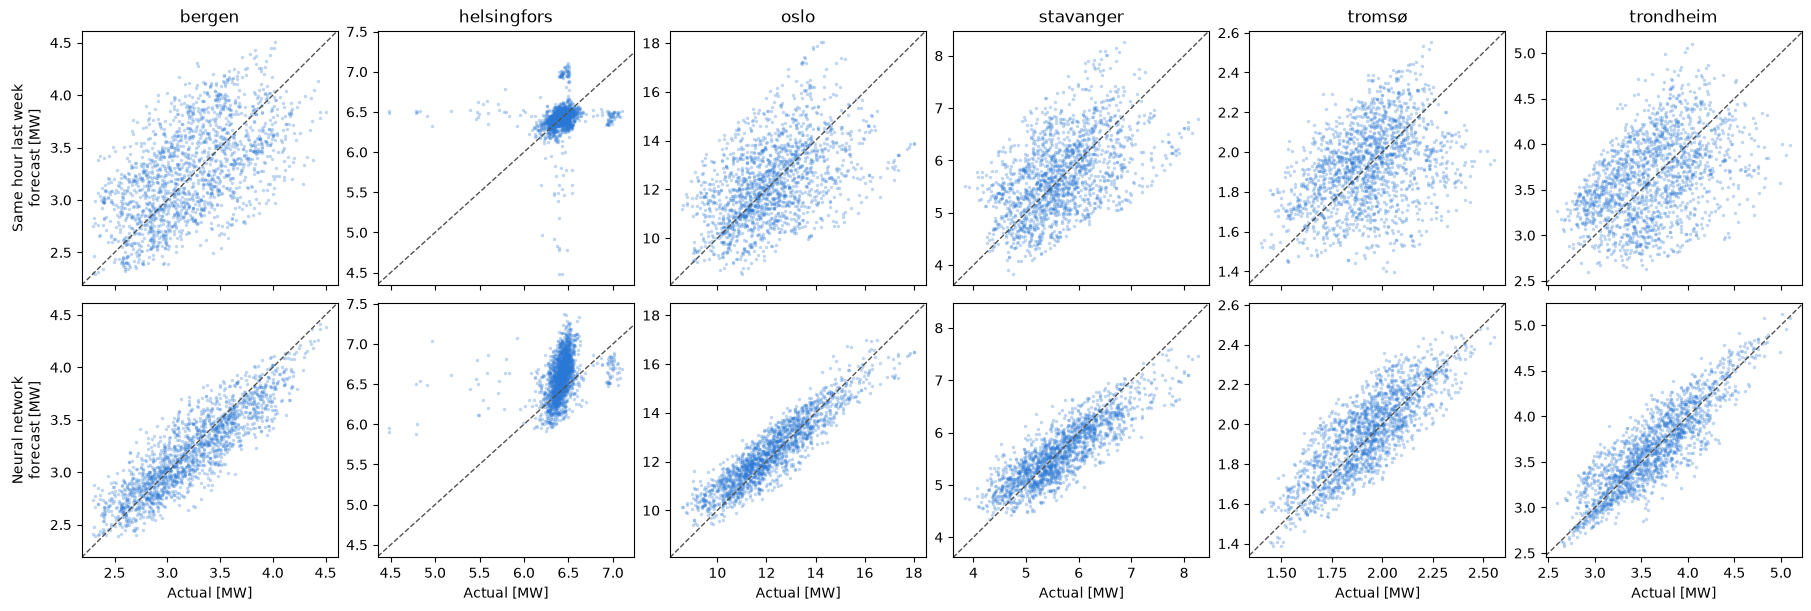

In [13]:
validator.plot_predicted_vs_actual_consumption()